# ML Zoomcamp 2026 – Homework 4

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mutual_info_score, accuracy_score, roc_curve, roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from pathlib import Path

np.set_printoptions(legacy='1.25')

In [2]:
data_path = Path("./data/course_lead_scoring_2026.csv").resolve()

df = pd.read_csv(data_path)
print(df.shape)
df.head()

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 526.0 KB


In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [6]:
categorical_features = df.select_dtypes(str).columns.to_list()
categorical_features

['lead_source', 'industry', 'employment_status', 'location']

In [7]:
numerical_features = df.select_dtypes(exclude=str).columns.to_list()
numerical_features.pop()
numerical_features

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [8]:
df[numerical_features] = df[numerical_features].fillna(0)
df[categorical_features] = df[categorical_features].fillna("NA")

In [9]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [10]:
all_features = categorical_features + numerical_features
all_features

['lead_source',
 'industry',
 'employment_status',
 'location',
 'annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [11]:
# Train-Val-Test split

SEED = 1

df_full_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    random_state=SEED
)
df_train, df_val = train_test_split(
    df_full_train, 
    test_size=0.25, 
    random_state=SEED
)

len(df_train), len(df_val), len(df_test), len(df_full_train)

(3000, 1000, 1000, 4000)

In [12]:
# Resetting indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Extract target
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values
# y_full_train = df_full_train["converted"].values

# Remove target from dataframes
df_train.drop("converted", axis=1, inplace=True)
df_val.drop("converted", axis=1, inplace=True)
df_test.drop("converted", axis=1, inplace=True)
# df_full_train.drop("converted", axis=1, inplace=True)

df_train.shape, df_val.shape, df_test.shape, df_full_train.shape

((3000, 8), (1000, 8), (1000, 8), (4000, 9))

## Q1 - ROC AUC feature importance

In [13]:
for nf in numerical_features:
    aoc_score = roc_auc_score(y_train, df_train[nf])
    print(f"{nf} --> {aoc_score:.4f}")

annual_income --> 0.6082
number_of_courses_viewed --> 0.7230
interaction_count --> 0.7649
lead_score --> 0.7882


## Q2 - Model training

In [14]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               3000 non-null   str    
 1   industry                  3000 non-null   str    
 2   employment_status         3000 non-null   str    
 3   location                  3000 non-null   str    
 4   annual_income             3000 non-null   float64
 5   number_of_courses_viewed  3000 non-null   int64  
 6   interaction_count         3000 non-null   int64  
 7   lead_score                3000 non-null   float64
dtypes: float64(2), int64(2), str(4)
memory usage: 293.1 KB


In [15]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient="records")
X_val = dv.transform(val_dict)

model = LogisticRegression(
    solver='liblinear', 
    C=1.0, 
    max_iter=1000, 
    random_state=SEED
)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1

In [16]:
y_pred = model.predict_proba(X_val)[:, 1]

In [17]:
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Q3 - Precision and Recall

Recall:
- Precision tells us the fraction of positive predictions that are correct
$$
\text{Precision} = \cfrac{TP}{TP + FP}
$$

- Recall measures the fraction of actual positive instances that we identified correctly
$$
\text{Recall} = \cfrac{TP}{TP + FN}
$$

In [18]:
np.arange(0.0, 1.01, step=0.01)

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [19]:
scores = []
thresholds = np.arange(0.0, 1.01, step=0.01)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ["threshold", "tp", "fp", "fn", "tn"]
df_scores = pd.DataFrame(scores, columns=columns)

df_scores["precision"] = df_scores["tp"] / (df_scores["tp"] + df_scores["fp"])
df_scores["recall"] = df_scores["tp"] / (df_scores["tp"] + df_scores["fn"])

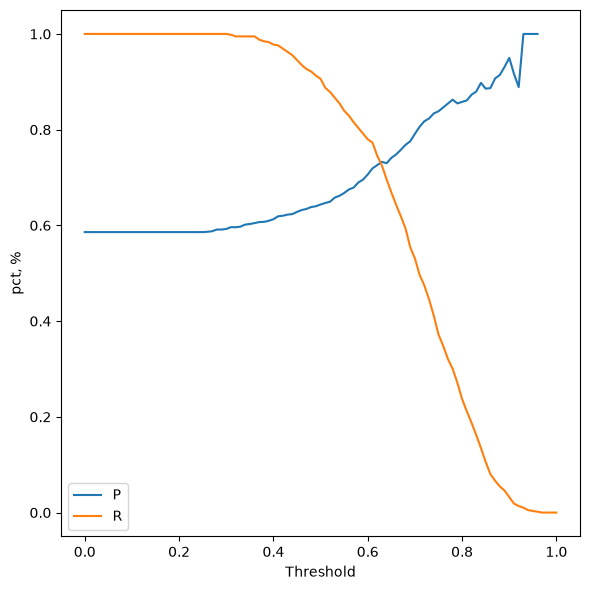

In [20]:
fix, ax = plt.subplots(figsize=(6, 6))

ax.plot(df_scores["threshold"], df_scores["precision"], label="P")
ax.plot(df_scores["threshold"], df_scores["recall"], label="R")

ax.set_xlabel("Threshold")
ax.set_ylabel("pct, %")
ax.legend()

plt.tight_layout()

In [21]:
df_scores["abs_diff"] = df_scores["precision"].subtract(df_scores["recall"], fill_value=0).abs().round(3)

In [22]:
df_scores[(df_scores["threshold"] >= 0.6) & (df_scores["threshold"] <= 0.7)][["threshold", "abs_diff"]]

,threshold,abs_diff
60,0.60,0.074
61,0.61,0.054
62,0.62,0.020
63,0.63,0.008
64,0.64,0.034
65,0.65,0.072
66,0.66,0.105
67,0.67,0.138
68,0.68,0.174
69,0.69,0.221


In [23]:
df_scores[(df_scores["threshold"] >= 0.6) & (df_scores["threshold"] <= 0.7)][["threshold", "abs_diff"]].sort_values(by="abs_diff")

,threshold,abs_diff
63,0.63,0.008
62,0.62,0.020
64,0.64,0.034
61,0.61,0.054
65,0.65,0.072
60,0.60,0.074
66,0.66,0.105
67,0.67,0.138
68,0.68,0.174
69,0.69,0.221


## Q4 - F1 score

$$
F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}
$$

In [24]:
p_times_r = df_scores["precision"] * df_scores["recall"]
p_plus_r = df_scores["precision"] + df_scores["recall"]

df_scores["f1_score"] = 2 * (p_times_r / p_plus_r)

In [25]:
df_scores["f1_score"].max()

0.7576158940397352

In [26]:
df_scores[["threshold", "f1_score"]].sort_values(by="f1_score", ascending=False).head(5)

,threshold,f1_score
41,0.41,0.757616
42,0.42,0.756325
43,0.43,0.756032
45,0.45,0.754768
44,0.44,0.754717


## Q5 - 5-Fold CV

In [27]:
all_features

['lead_source',
 'industry',
 'employment_status',
 'location',
 'annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [31]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[all_features].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(
        solver="liblinear", 
        C=C, 
        max_iter=1000, 
        random_state=SEED
    )
    model.fit(X_train, y_train)
    
    return dv, model


def predict(df, dv, model):
    dicts = df[all_features].to_dict(orient="records")

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [32]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train["converted"].values
    y_val = df_val["converted"].values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [37]:
scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [40]:
np.std(scores).round(5)

0.00685

## Q6 - Hyperparameter Tuning

In [41]:
from tqdm.auto import tqdm

In [43]:
parameters = [0.000001, 0.001, 1]

for C in tqdm(parameters):
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=SEED
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train["converted"].values
        y_val = df_val["converted"].values
    
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(f"{C} --> MEAN: {np.mean(scores):.3f}, STDEV: {np.std(scores):.3f}")

  0%|          | 0/3 [00:00<?, ?it/s]

1e-06 --> MEAN: 0.617, STDEV: 0.019
0.001 --> MEAN: 0.749, STDEV: 0.010
1 --> MEAN: 0.732, STDEV: 0.007
